# FarmTech Neural Vision — Ir Além 2

**Transfer Learning, Fine-Tuning e segmentação automática**

**Arquivo:** `ir_alem_2/notebook/ir_alem_2_transfer_learning_segmentacao.ipynb`

**Grupo:** Edemir Sufiatti (RM571375), Georgia Mendes Rocha (RM573281), Carlos Magnus Costa Amaral (RM573978) e Marina Leme Soares (RM570461).

## Objetivo

A Entrega 1 usou o YOLOv5 para **localizar** banana e milho. Aqui a tarefa é outra: **classificar** a foto inteira como banana ou milho, usando as mesmas 80 imagens (32 de treino, 4 de validação e 4 de teste por classe).

O enunciado pede duas abordagens, cada uma com uma hipótese:

| | Abordagem 1 | Abordagem 2 |
| --- | --- | --- |
| **O que muda** | Uma rede grande pré-treinada no ImageNet (VGG16), com Transfer Learning e Fine-Tuning | O fundo da foto é apagado por uma máscara de segmentação antes da classificação |
| **Hipótese** | A rede pré-treinada classifica melhor que uma CNN treinada do zero? | Mostrar à rede só os pixels do objeto facilita a classificação? |
| **Comparação** | CNN do zero × VGG16 congelada × VGG16 com Fine-Tuning | Os mesmos três modelos com a foto original × a foto sem fundo |

São três arquiteturas avaliadas em duas versões da base, totalizando **seis combinações modelo × base**, todas avaliadas nas mesmas 8 fotos de teste.

### Fluxo

<img src="https://raw.githubusercontent.com/EdeSufiatti/farmtech_neural_vision/main/ir_alem_2/assets/fluxo_ir_alem.png" alt="Fluxo do Ir Além 2" width="900">

A figura também está no repositório, em `ir_alem_2/assets/fluxo_ir_alem.png`.

## 1. Antes de executar

**Pré-requisito: a Entrega 1 já foi executada.** A segmentação usa o `best.pt` que o notebook da Entrega 1 grava em `Meu Drive/FarmTech_Neural_Vision/runs/train/exp60`, o treino de 60 épocas escolhido na conclusão da Entrega 1.

**GPU.** Abra o menu ao lado de RAM e Disco, clique em **Alterar o tipo de ambiente de execução**, escolha **GPUs: T4** e depois **Salvar**.

**Drive.** As pastas são as mesmas da Entrega 1, na conta **edefiapia@gmail.com**:

https://drive.google.com/drive/folders/18FQL7_woTacQxS92qzcNKTtFyj0Mj8NZ?usp=drive_link

Se for executar com outra conta Google, abra o link acima, clique no nome da pasta e escolha **Organizar → Adicionar atalho → Meu Drive**. O atalho faz a pasta aparecer em `Meu Drive/FarmTech_Neural_Vision`, que é o caminho usado aqui. Sem permissão de edição, as células que gravam resultados vão falhar.

**O que este notebook grava no Drive**, dentro de `FarmTech_Neural_Vision/ir_alem/`:

```text
ir_alem/
├── dataset_segmentado/   fotos com o fundo apagado (mesma divisão train/val/test)
├── mascaras/             máscaras em preto e branco geradas pelo SAM
└── figuras/              exemplos de segmentação, curvas, matrizes de confusão e comparação
```

Execute as células em ordem. Se a sessão cair, recomece pela seção 2.

## 2. Montar o Drive e conferir o dataset

A célula monta o Drive, define as pastas usadas no notebook inteiro e confere se cada conjunto tem a quantidade esperada de fotos e rótulos.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

RAIZ = Path('/content/drive/MyDrive/FarmTech_Neural_Vision')  # pasta principal do projeto no Drive
DATASET = RAIZ / 'dataset'                                     # fotos originais da Entrega 1
SAIDA = RAIZ / 'ir_alem'                                       # tudo o que este notebook grava
DATASET_SEG = SAIDA / 'dataset_segmentado'                     # fotos com o fundo apagado
MASCARAS = SAIDA / 'mascaras'                                  # máscaras do SAM
FIGURAS = SAIDA / 'figuras'                                    # imagens geradas para o relatório

CLASSES = ['banana', 'milho']                    # índice 0 = banana, 1 = milho (mesma numeração da Entrega 1)
ESPERADO = {'train': 32, 'val': 4, 'test': 4}    # fotos por classe em cada conjunto

FIGURAS.mkdir(parents=True, exist_ok=True)

erros = []
for conjunto, n in ESPERADO.items():
    for classe in CLASSES:
        fotos = sorted((DATASET / conjunto / 'images' / classe).glob('*.jpg'))
        rotulos = sorted((DATASET / conjunto / 'labels' / classe).glob('*.txt'))
        print(f'{conjunto:5s} {classe:6s} fotos: {len(fotos):2d}  rótulos: {len(rotulos):2d}')
        if len(fotos) != n or {p.stem for p in fotos} != {p.stem for p in rotulos}:
            erros.append(f'{conjunto}/{classe}')

if erros:
    raise RuntimeError('Dataset incompleto em: ' + ', '.join(erros))
print('Dataset conferido: 80 fotos com rótulo de mesmo nome.')

Mounted at /content/drive
train banana fotos: 32  rótulos: 32
train milho  fotos: 32  rótulos: 32
val   banana fotos:  4  rótulos:  4
val   milho  fotos:  4  rótulos:  4
test  banana fotos:  4  rótulos:  4
test  milho  fotos:  4  rótulos:  4
Dataset conferido: 80 fotos com rótulo de mesmo nome.


In [2]:
import torch

# A segmentação e os treinos dependem da GPU. Na CPU, os 6 treinos levam muito mais tempo.
print('GPU disponível:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('Nome da GPU:', torch.cuda.get_device_name(0))
else:
    print('Sem GPU. Mude o ambiente de execução para T4 e recomece pela seção 2.')

GPU disponível: True
Nome da GPU: Tesla T4


# Parte A — Segmentação automática

O enunciado pede uma rede de segmentação que crie a máscara do objeto **de forma automática**, e depois o uso dessa máscara para apagar o fundo.

### Por que o SAM

O **SAM (Segment Anything Model)**, da Meta, é a rede de segmentação do Capítulo 10. Ele foi treinado em mais de um bilhão de máscaras e segmenta objetos que nunca viu, sem treino adicional. Isso importa aqui, porque não temos máscaras desenhadas à mão para treinar uma U-Net ou uma Mask R-CNN.

### Por que o YOLOv5 da Entrega 1 entra junto

Sozinho, o SAM segmenta *tudo* o que encontra na foto: folhas, prato, mesa, palha. Para saber **qual** objeto recortar, ele precisa de uma indicação de onde o objeto está. Essa indicação vem do `best.pt` da Entrega 1:

1. O YOLOv5 encontra as caixas de banana ou milho na foto.
2. Cada caixa é enviada ao SAM, que desenha o contorno exato do objeto dentro dela.
3. As máscaras de todas as caixas são unidas, porque há fotos com um cacho inteiro ou várias espigas.
4. Os pixels fora da máscara viram preto.

Nenhuma máscara é desenhada à mão. Os rótulos do MakeSense não entram na segmentação: só servem, na seção A4, para conferir a qualidade das máscaras.

**A classe prevista pelo YOLOv5 é descartada.** Só a posição da caixa é usada. Assim, o classificador não recebe a resposta pronta.

## A1. Instalar o YOLOv5 e o pacote do SAM

O `best.pt` da Entrega 1 foi treinado com o repositório oficial do YOLOv5, por isso ele é clonado aqui na mesma revisão fixada na Entrega 1 (`4add2aff`). O SAM vem do pacote `ultralytics`. Se o instalador pedir uma opção de biblioteca, escolha **3**.

In [3]:
import os

REVISAO_YOLO = '4add2aff'  # mesma revisão do YOLOv5 fixada no notebook da Entrega 1

# Clona o YOLOv5 só na primeira vez desta sessão e fixa a revisão usada no treino do best.pt.
if not os.path.isdir('/content/yolov5'):
    !git clone -q https://github.com/ultralytics/yolov5.git /content/yolov5
!git -C /content/yolov5 checkout -q --detach {REVISAO_YOLO}

!pip install -q -r /content/yolov5/requirements.txt   # dependências do YOLOv5
!pip install -q ultralytics                           # pacote que traz o SAM

print('Revisão do YOLOv5:', os.popen('git -C /content/yolov5 rev-parse --short HEAD').read().strip())
print('YOLOv5 pronto:', os.path.isfile('/content/yolov5/hubconf.py'))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 9.5 MB/s eta 0:00:00
Revisão do YOLOv5: 4add2aff
YOLOv5 pronto: True


## A2. Carregar o detector e o SAM

`SIMULACAO` indica qual treino da Entrega 1 fornece o `best.pt`. Aqui é o `exp60`, o treino de 60 épocas escolhido na conclusão da Entrega 1.

`detector.conf = 0.25` é a confiança mínima para aceitar uma caixa. O SAM usado é o `sam_b.pt` (versão *base*), baixado automaticamente na primeira execução.

In [4]:
import torch
from ultralytics import SAM

SIMULACAO = 'exp60'  # modelo de 60 épocas, o escolhido na conclusão da Entrega 1
PESOS_YOLO = RAIZ / 'runs' / 'train' / SIMULACAO / 'weights' / 'best.pt'

if not PESOS_YOLO.is_file():
    raise FileNotFoundError(f'Não encontrei {PESOS_YOLO}. Execute a Entrega 1 até a seção 10 (gravar o treino no Drive).')

# Carrega o best.pt usando o código do repositório YOLOv5 clonado na célula anterior.
detector = torch.hub.load('/content/yolov5', 'custom', path=str(PESOS_YOLO), source='local')
detector.conf = 0.25           # caixas com confiança menor que 25% são ignoradas

segmentador = SAM('sam_b.pt')  # Segment Anything, versão base

print('Detector:', PESOS_YOLO)
print('Segmentador: SAM base')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLOv5 🚀 v7.0-555-g4add2aff Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
Detector: /content/drive/MyDrive/FarmTech_Neural_Vision/runs/train/exp60/weights/best.pt
Segmentador: SAM base


## A3. Segmentar as 80 fotos

Algumas fotos de milho têm quase 9.000 pixels de lado. Antes de segmentar, o lado maior é reduzido para 1.024 pixels. Os classificadores usam 224 × 224, então essa redução não tira informação que eles usariam, e o resultado gravado no Drive fica bem menor.

Se o detector não encontrar nenhuma caixa, a imagem inteira é usada como região de interesse (ROI) para o SAM. Nesse caso, o resultado fica mais dependente da interpretação do segmentador e deve ser inspecionado visualmente. Essas fotos ficam marcadas na tabela da seção A4.

A célula grava a foto sem fundo em `ir_alem/dataset_segmentado` e a máscara em `ir_alem/mascaras`. A divisão `train`, `val` e `test` é a mesma da base original.

### Correção de máscaras invertidas

Na primeira execução deste notebook, a inspeção visual das fotos sem fundo mostrou um problema: em algumas fotos, o SAM devolveu **o fundo no lugar do objeto**. A banana ou a espiga virava um buraco preto, e as folhas, a palha ou o fundo branco de estúdio ficavam. No teste, isso aconteceu em `banana_01`, `banana_03` e `milho_03`; no treino, em fotos como `banana_18` e `banana_23`. Acontece quando o objeto ocupa quase toda a caixa: dentro dela, o SAM fica sem referência clara do que é objeto e do que é fundo.

A conferência da seção A4 não pegou todos esses casos. A `banana_03`, por exemplo, teve IoU de caixa 0,89 com a máscara invertida, porque o retângulo em volta do fundo era parecido com o retângulo em volta da banana. Por isso a correção usa outra regra, aplicada a cada caixa:

1. O que o SAM marcou **fora da caixa** é descartado. O objeto está dentro dela.
2. Mede-se quanto da **borda da caixa** (uma faixa fina, de 3% do lado menor) ficou marcada como objeto. Um objeto de verdade encosta na borda em alguns pontos. O fundo envolve o objeto e cobre quase a borda inteira.
3. Se mais de **60%** da borda estiver marcada, a máscara foi considerada invertida e é desinvertida dentro da caixa. A troca só é feita se a máscara desinvertida ocupar mais de 5% da caixa; assim, um objeto que preenche a caixa inteira não é apagado.
4. Uma limpeza leve (abertura e fechamento morfológicos, 5 × 5 pixels) remove pontinhos soltos e fecha furos pequenos, o "pixelado" que aparecia nas fotos de fundo branco.

A tabela da seção A4 mostra quantas máscaras foram desinvertidas em cada foto.

In [5]:
import cv2
import numpy as np

LADO_MAX = 1024  # lado maior da foto antes de segmentar


def ler_reduzida(caminho):
    """Lê a foto com OpenCV (que já aplica a rotação EXIF) e reduz o lado maior para LADO_MAX."""
    img = cv2.imread(str(caminho))                     # formato BGR, padrão do OpenCV
    altura, largura = img.shape[:2]
    escala = min(1.0, LADO_MAX / max(altura, largura))  # nunca aumenta foto pequena
    if escala < 1.0:
        novo_tamanho = (round(largura * escala), round(altura * escala))
        img = cv2.resize(img, novo_tamanho, interpolation=cv2.INTER_AREA)
    return img


def caixas_do_detector(img_bgr):
    """Devolve as caixas [x1, y1, x2, y2] encontradas pelo YOLOv5. A classe prevista é descartada."""
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)  # o YOLOv5 espera RGB quando recebe uma matriz
    resultado = detector(rgb, size=640)              # mesmo tamanho de imagem usado no treino da Entrega 1
    return resultado.xyxy[0][:, :4].cpu().numpy()    # colunas: x1, y1, x2, y2 (conf e classe ficam de fora)


LIMITE_INVERSAO = 0.6                                   # borda marcada acima disso = máscara invertida
LIMPEZA = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))  # elemento da limpeza morfológica


def faixa_da_borda(x1, y1, x2, y2, altura, largura):
    """Faixa fina ao longo das quatro bordas da caixa (True = pixel da faixa)."""
    espessura = max(2, int(0.03 * min(x2 - x1, y2 - y1)))   # 3% do lado menor da caixa
    faixa = np.zeros((altura, largura), dtype=bool)
    faixa[y1:y2, x1:x2] = True
    faixa[y1 + espessura:y2 - espessura, x1 + espessura:x2 - espessura] = False
    return faixa


def mascara_do_sam(img_bgr, caixas):
    """Pede ao SAM uma máscara por caixa, desinverte as que pegaram o fundo e junta todas.

    Devolve a máscara final (1 = objeto, 0 = fundo) e quantas máscaras foram desinvertidas.
    """
    altura, largura = img_bgr.shape[:2]
    resultado = segmentador(img_bgr, bboxes=caixas.tolist(), verbose=False)[0]
    mascaras = None if resultado.masks is None else resultado.masks.data.cpu().numpy()

    final = np.zeros((altura, largura), dtype=np.uint8)
    invertidas = 0
    for i, (x1, y1, x2, y2) in enumerate(caixas):
        x1, y1 = max(0, int(x1)), max(0, int(y1))                       # caixa em pixels inteiros,
        x2, y2 = min(largura, int(np.ceil(x2))), min(altura, int(np.ceil(y2)))  # dentro da foto
        if x2 - x1 < 8 or y2 - y1 < 8:                                  # caixa minúscula: ignora
            continue
        dentro = np.zeros((altura, largura), dtype=np.uint8)
        dentro[y1:y2, x1:x2] = 1                                        # 1 = pixel dentro da caixa

        if mascaras is None or i >= len(mascaras):                      # segurança: sem máscara do SAM,
            final |= dentro                                             # usa o retângulo da caixa
            continue

        m = mascaras[i].astype(np.uint8)
        if m.shape != (altura, largura):                                # garante o tamanho da foto
            m = cv2.resize(m, (largura, altura), interpolation=cv2.INTER_NEAREST)
        m = m * dentro                                                  # 1) descarta o que está fora da caixa

        faixa = faixa_da_borda(x1, y1, x2, y2, altura, largura)
        if m[faixa].mean() > LIMITE_INVERSAO:                           # 2) e 3) borda quase toda marcada:
            desinvertida = (1 - m) * dentro                             #    pegou o fundo, então desinverte,
            if desinvertida.sum() > 0.05 * dentro.sum():                #    desde que sobre um objeto de verdade
                m = desinvertida                                        #    (mais de 5% da caixa)
                invertidas += 1
        final |= m                                                      # união com as outras caixas

    final = cv2.morphologyEx(final, cv2.MORPH_OPEN, LIMPEZA)            # 4) remove pontinhos soltos
    final = cv2.morphologyEx(final, cv2.MORPH_CLOSE, LIMPEZA)           #    e fecha furos pequenos
    return final, invertidas


def aplicar_mascara(img_bgr, mascara):
    """Mantém os pixels do objeto e pinta o fundo de preto."""
    recortada = img_bgr.copy()
    recortada[mascara == 0] = 0
    return recortada

In [6]:
import time

registros = []  # uma linha por foto, usada na conferência da seção A4
inicio = time.time()

for conjunto in ESPERADO:
    for classe in CLASSES:
        pasta_img = DATASET_SEG / conjunto / 'images' / classe
        pasta_msk = MASCARAS / conjunto / classe
        pasta_img.mkdir(parents=True, exist_ok=True)
        pasta_msk.mkdir(parents=True, exist_ok=True)

        for foto in sorted((DATASET / conjunto / 'images' / classe).glob('*.jpg')):
            img = ler_reduzida(foto)
            altura, largura = img.shape[:2]

            caixas = caixas_do_detector(img)
            sem_deteccao = len(caixas) == 0
            if sem_deteccao:  # nenhuma caixa: a foto inteira vira o pedido ao SAM
                caixas = np.array([[0, 0, largura - 1, altura - 1]], dtype=np.float32)

            mascara, invertidas = mascara_do_sam(img, caixas)
            recortada = aplicar_mascara(img, mascara)

            cv2.imwrite(str(pasta_img / foto.name), recortada, [cv2.IMWRITE_JPEG_QUALITY, 95])
            cv2.imwrite(str(pasta_msk / (foto.stem + '.png')), mascara * 255)

            registros.append({
                'conjunto': conjunto,
                'classe': classe,
                'foto': foto.name,
                'caixas_detectadas': 0 if sem_deteccao else len(caixas),
                'sem_deteccao': sem_deteccao,
                'mascaras_desinvertidas': invertidas,
                'area_objeto_%': round(100 * mascara.mean(), 1),  # fração da foto coberta pela máscara
                'largura': largura,
                'altura': altura,
                'mascara': mascara,  # guardada só em memória, para a conferência a seguir
            })

        print(f'{conjunto}/{classe}: {len(list(pasta_img.glob("*.jpg")))} fotos segmentadas')

print(f'Segmentação concluída em {time.time() - inicio:.0f} s')

train/banana: 32 fotos segmentadas
train/milho: 32 fotos segmentadas
val/banana: 4 fotos segmentadas
val/milho: 4 fotos segmentadas
test/banana: 4 fotos segmentadas
test/milho: 4 fotos segmentadas
Segmentação concluída em 187 s


## A4. Conferência das máscaras

Não existem máscaras desenhadas à mão para comparar. Os rótulos do MakeSense, porém, têm a caixa de cada objeto. A conferência compara duas caixas:

- **caixa da máscara:** o menor retângulo que contém todos os pixels da máscara do SAM;
- **caixa rotulada:** o menor retângulo que contém todas as caixas marcadas no MakeSense para aquela foto.

A medida é o **IoU** (Capítulo 10): a área em comum dividida pela área total das duas caixas. O valor 1 indica que as caixas são idênticas. Abaixo de 0,5, a máscara pegou outra região ou só parte do objeto, e a foto merece ser olhada.

O IoU de caixa não mede o contorno pixel a pixel. Ele só indica se a máscara está no lugar certo e tem o tamanho certo. Ele também **não detecta máscara invertida** quando o fundo ocupa um retângulo parecido com o do objeto (veja a seção A3). A célula lista ainda as fotos em que a correção desinverteu alguma máscara.

In [7]:
import pandas as pd


def caixa_rotulada(conjunto, classe, nome_foto, largura, altura):
    """Junta as caixas do MakeSense (formato YOLO, valores de 0 a 1) num único retângulo em pixels."""
    arquivo = DATASET / conjunto / 'labels' / classe / (Path(nome_foto).stem + '.txt')
    linhas = [l.split() for l in arquivo.read_text().splitlines() if l.strip()]
    x1s, y1s, x2s, y2s = [], [], [], []
    for _, xc, yc, w, h in (map(float, l[:5]) for l in linhas):
        x1s.append((xc - w / 2) * largura)
        y1s.append((yc - h / 2) * altura)
        x2s.append((xc + w / 2) * largura)
        y2s.append((yc + h / 2) * altura)
    return [min(x1s), min(y1s), max(x2s), max(y2s)]


def caixa_da_mascara(mascara):
    """Menor retângulo que contém todos os pixels da máscara."""
    ys, xs = np.where(mascara > 0)
    if len(xs) == 0:
        return None
    return [xs.min(), ys.min(), xs.max(), ys.max()]


def iou(a, b):
    """Área em comum dividida pela área total das duas caixas."""
    if a is None or b is None:
        return 0.0
    largura = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    altura = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    comum = largura * altura
    total = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - comum
    return comum / total if total > 0 else 0.0


for r in registros:
    rotulada = caixa_rotulada(r['conjunto'], r['classe'], r['foto'], r['largura'], r['altura'])
    r['iou_caixa'] = round(iou(caixa_da_mascara(r['mascara']), rotulada), 2)

conferencia = pd.DataFrame(registros).drop(columns=['mascara', 'largura', 'altura'])

print('IoU médio por classe e conjunto:')
display(conferencia.pivot_table(index='classe', columns='conjunto', values='iou_caixa', aggfunc='mean').round(2))

print('Fotos em que o detector não achou caixa:', int(conferencia['sem_deteccao'].sum()))

corrigidas = conferencia[conferencia['mascaras_desinvertidas'] > 0]
print(f'Fotos com máscara desinvertida pela correção: {len(corrigidas)}')
display(corrigidas[['conjunto', 'classe', 'foto', 'mascaras_desinvertidas', 'area_objeto_%', 'iou_caixa']])

revisar = conferencia[conferencia['iou_caixa'] < 0.5]
print(f'Fotos com IoU abaixo de 0,5 (olhar com atenção): {len(revisar)}')
display(revisar)

IoU médio por classe e conjunto:


conjunto,test,train,val
classe,,,
banana,0.54,0.73,0.57
milho,0.62,0.81,0.77


Fotos em que o detector não achou caixa: 4
Fotos com máscara desinvertida pela correção: 6


,conjunto,classe,foto,mascaras_desinvertidas,area_objeto_%,iou_caixa
2,train,banana,banana_03.jpg,1,45.4,0.83
5,train,banana,banana_06.jpg,1,40.7,0.36
22,train,banana,banana_23.jpg,1,48.1,0.86
55,train,milho,milho_24.jpg,1,16.8,0.93
72,test,banana,banana_01.jpg,1,36.1,0.22
74,test,banana,banana_03.jpg,1,45.6,0.82


Fotos com IoU abaixo de 0,5 (olhar com atenção): 10


,conjunto,classe,foto,caixas_detectadas,sem_deteccao,mascaras_desinvertidas,area_objeto_%,iou_caixa
5,train,banana,banana_06.jpg,0,True,1,40.7,0.36
7,train,banana,banana_08.jpg,2,False,0,31.0,0.35
10,train,banana,banana_11.jpg,1,False,0,0.5,0.48
26,train,banana,banana_27.jpg,1,False,0,6.6,0.16
38,train,milho,milho_07.jpg,1,False,0,0.4,0.23
56,train,milho,milho_25.jpg,2,False,0,8.0,0.29
66,val,banana,banana_03.jpg,1,False,0,3.0,0.03
72,test,banana,banana_01.jpg,0,True,1,36.1,0.22
73,test,banana,banana_02.jpg,1,False,0,6.8,0.20
76,test,milho,milho_01.jpg,2,False,0,17.0,0.49


## A5. Original, máscara e foto sem fundo

O enunciado pede essa demonstração para algumas imagens da base. Aqui aparecem as 8 fotos de teste: na primeira coluna a foto original, na segunda a máscara (branco = objeto) e na terceira a foto com o fundo apagado.

A figura fica gravada em `ir_alem/figuras/exemplos_segmentacao.png`.

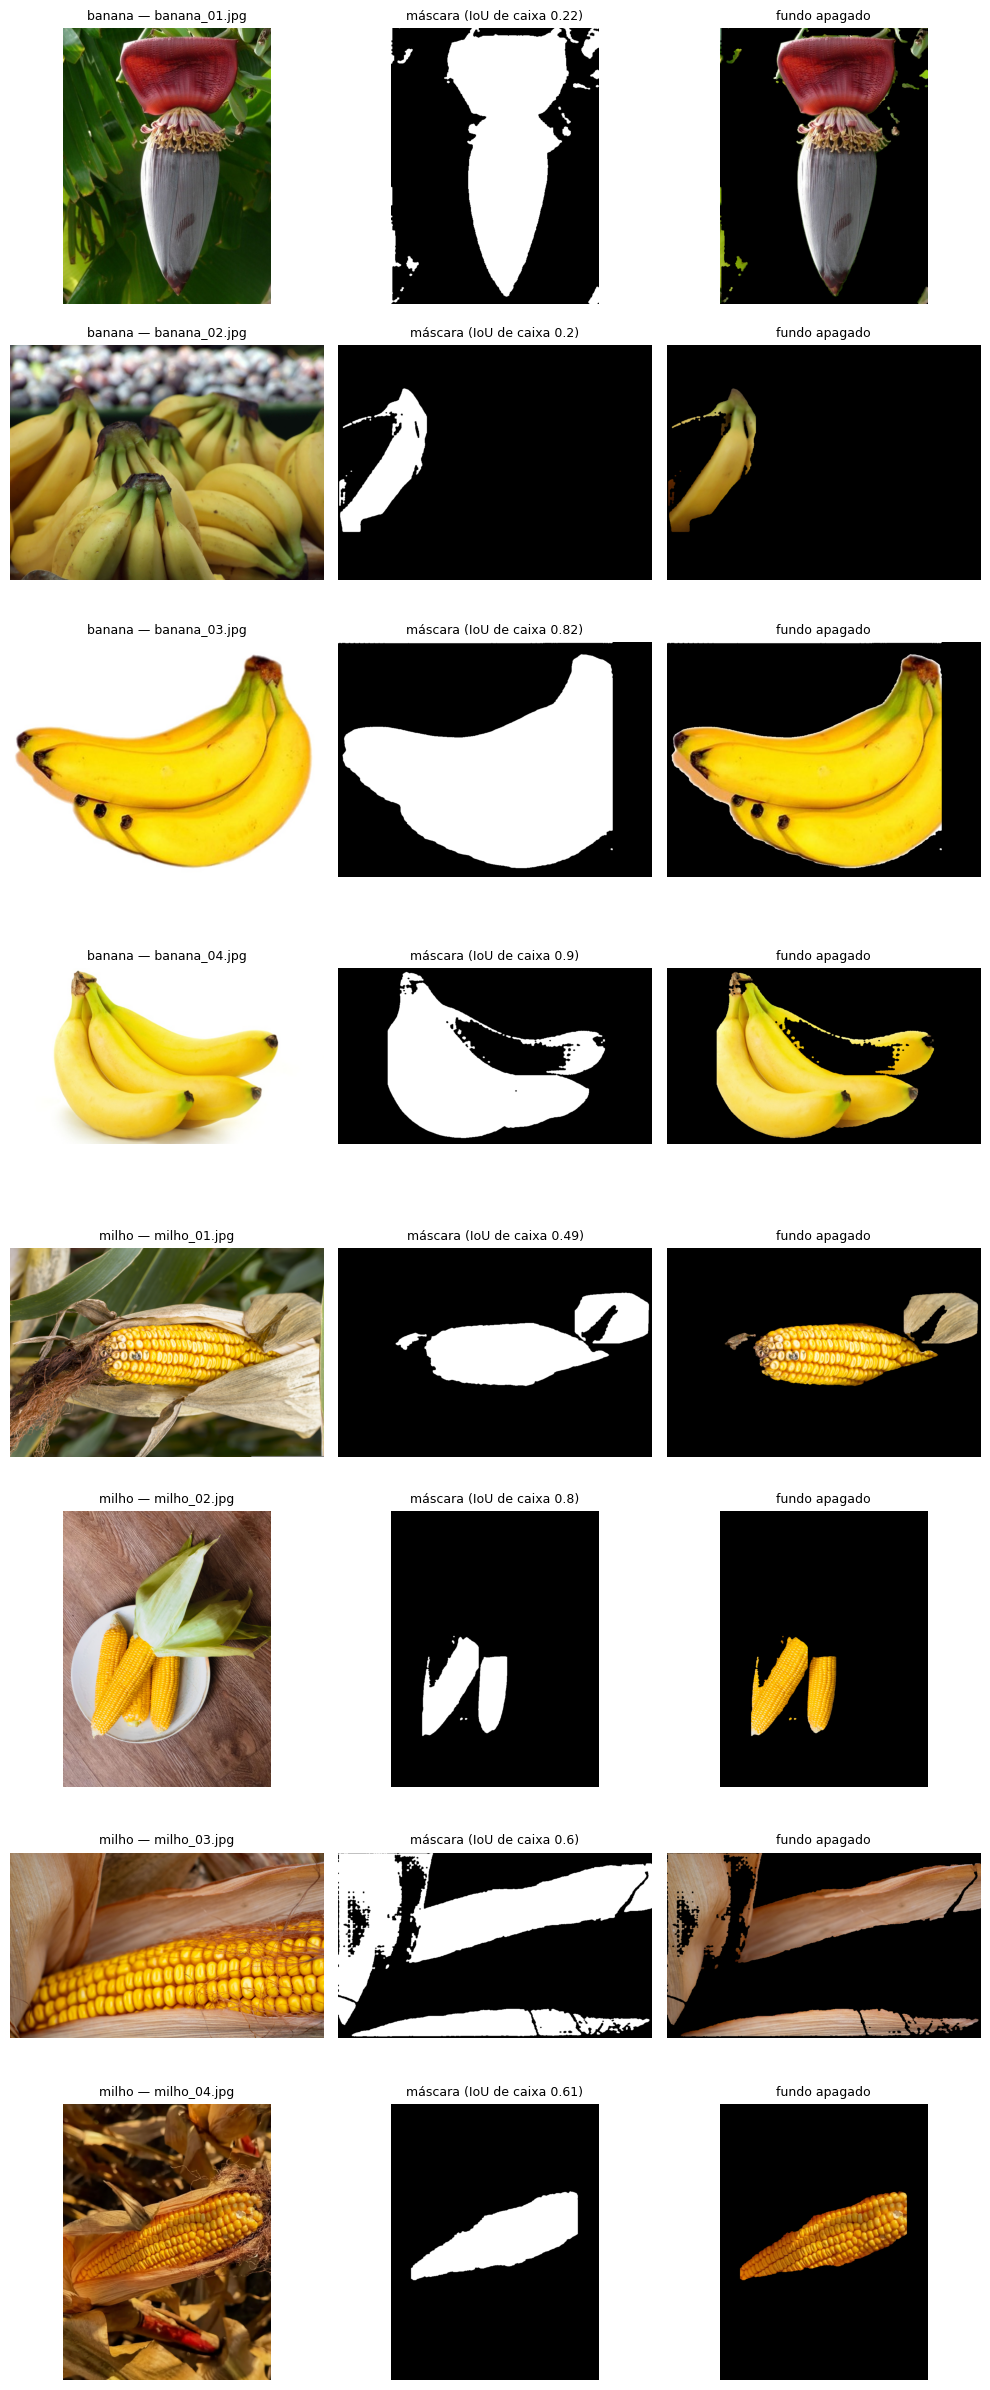

In [8]:
import matplotlib.pyplot as plt

exemplos = [r for r in registros if r['conjunto'] == 'test']  # 4 bananas e 4 milhos

fig, eixos = plt.subplots(len(exemplos), 3, figsize=(10, 3 * len(exemplos)))
for linha, r in zip(eixos, exemplos):
    original = ler_reduzida(DATASET / 'test' / 'images' / r['classe'] / r['foto'])
    recortada = aplicar_mascara(original, r['mascara'])
    paineis = [
        (cv2.cvtColor(original, cv2.COLOR_BGR2RGB), f"{r['classe']} — {r['foto']}"),
        (r['mascara'], f"máscara (IoU de caixa {r['iou_caixa']})"),
        (cv2.cvtColor(recortada, cv2.COLOR_BGR2RGB), 'fundo apagado'),
    ]
    for eixo, (imagem, titulo) in zip(linha, paineis):
        eixo.imshow(imagem, cmap='gray')
        eixo.set_title(titulo, fontsize=9)
        eixo.axis('off')

plt.tight_layout()
plt.savefig(FIGURAS / 'exemplos_segmentacao.png', dpi=110)
plt.show()

## A6. Liberar a GPU

O detector e o SAM rodam em PyTorch. Os classificadores da Parte B rodam em TensorFlow. A célula apaga os modelos de segmentação e libera a memória da GPU antes de o TensorFlow começar.

In [9]:
import gc

del detector, segmentador  # os modelos de segmentação não são mais usados
for r in registros:
    r.pop('mascara', None)  # as máscaras já estão gravadas no Drive
gc.collect()
torch.cuda.empty_cache()
print('Memória da GPU liberada para o TensorFlow.')

Memória da GPU liberada para o TensorFlow.


# Parte B — Classificadores

Cada um dos três modelos é treinado duas vezes: uma com as fotos originais e outra com as fotos sem fundo.

| Modelo | O que é |
| --- | --- |
| **CNN do zero** | Rede pequena, com pesos aleatórios no início. Aprende só com as 64 fotos de treino |
| **VGG16 Transfer** | VGG16 treinada no ImageNet, toda congelada. Só a camada de decisão final é treinada |
| **VGG16 Fine-Tuning** | Continua do modelo anterior, liberando o último bloco da VGG16 para reajuste |

A CNN do zero segue a mesma ideia da Entrega 2 e do Capítulo 9: blocos de convolução e *pooling*, seguidos da camada de decisão. Ela é refeita aqui para que as três redes usem exatamente as mesmas fotos, o mesmo tamanho de imagem e a mesma avaliação.

## B1. TensorFlow

`set_memory_growth` faz o TensorFlow ocupar a memória da GPU aos poucos, em vez de reservar tudo de uma vez. A semente 42 deixa os resultados repetíveis dentro da mesma sessão. Ainda assim, pequenas diferenças entre execuções na GPU são normais.

In [10]:
import tensorflow as tf

# Ocupa a memória da GPU aos poucos (precisa ser feito antes do primeiro uso da GPU pelo TensorFlow).
for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # a GPU já estava em uso por uma execução anterior desta célula

print('TensorFlow', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## B2. Carregar as fotos

As 80 fotos são pequenas depois de reduzidas e cabem na memória, como no exemplo do Capítulo 9. Cada foto é:

1. lida com OpenCV, que aplica a rotação EXIF (uma das fotos de milho da validação vem girada no arquivo);
2. convertida de BGR para RGB;
3. redimensionada para **224 × 224**, o tamanho de entrada da VGG16. O mesmo tamanho é usado na CNN do zero, para que a comparação seja justa.

O rótulo vem do nome da pasta: banana = 0 e milho = 1.

In [11]:
import numpy as np
import cv2

TAMANHO = 224  # lado da imagem de entrada das três redes


def carregar(pasta_base, conjunto):
    """Lê as fotos de pasta_base/conjunto/images/<classe> e devolve imagens, rótulos e caminhos."""
    imagens, rotulos, caminhos = [], [], []
    for indice, classe in enumerate(CLASSES):
        for foto in sorted((pasta_base / conjunto / 'images' / classe).glob('*.jpg')):
            img = cv2.imread(str(foto))                    # aplica a rotação EXIF
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)     # as redes do Keras esperam RGB
            img = cv2.resize(img, (TAMANHO, TAMANHO), interpolation=cv2.INTER_AREA)
            imagens.append(img)
            rotulos.append(indice)
            caminhos.append(foto)
    return np.array(imagens, dtype='float32'), np.array(rotulos, dtype='float32'), caminhos


# Conferência rápida com a base original.
x, y, _ = carregar(DATASET, 'train')
print('Treino original:', x.shape, '| bananas:', int((y == 0).sum()), '| milhos:', int((y == 1).sum()))

Treino original: (64, 224, 224, 3) | bananas: 32 | milhos: 32


## B3. Os três modelos

### Aumento de dados

São só 64 fotos de treino. A cada época, a rede vê cada foto com pequenas variações aleatórias: espelhada na horizontal, girada até 10% e com zoom de até 10%. Isso reduz o risco de a rede decorar as fotos (*overfitting*). As camadas de aumento só agem no treino. Na validação e no teste, a foto entra como está.

### CNN do zero

Três blocos de convolução 3 × 3 com 16, 32 e 64 filtros, cada um seguido de *max pooling*. A primeira camada divide os pixels por 255. No fim, `GlobalAveragePooling2D` resume cada mapa de características num único número, no lugar do `Flatten` do Capítulo 9. Com 64 fotos, o `Flatten` criaria milhões de pesos na camada densa e a rede decoraria o treino.

### VGG16 — escolha da arquitetura

O enunciado permite VGG, Inception, MobileNet ou outra rede do TensorFlow. A escolha foi a **VGG16**, por três motivos:

1. É a rede usada no exemplo de Transfer Learning do Capítulo 9.
2. Foi treinada no ImageNet, que tem banana e espiga de milho (*corn*, *ear*) entre as suas 1.000 classes. As características que ela aprendeu já servem para esses objetos.
3. A arquitetura é organizada em **5 blocos** de convolução bem separados (`block1` a `block5`). Isso deixa claro onde congelar e onde liberar no Fine-Tuning.

A MobileNet seria mais leve, mas na T4 o tamanho da VGG16 (14,7 milhões de pesos) não é problema, e as 80 fotos treinam em poucos minutos.

`include_top=False` remove a camada de decisão original, de 1.000 classes. No lugar dela entram `GlobalAveragePooling2D`, `Dropout` de 30% e um neurônio com `sigmoid`, que dá a probabilidade de a foto ser milho.

### Pré-processamento exigido pela VGG16

A VGG16 foi treinada com fotos em ordem de cores BGR e com a média de cada cor do ImageNet subtraída. `preprocess_input` faz essa mesma conversão. Sem ela, a rede recebe números numa escala diferente da que conhece e as características extraídas perdem sentido. A CNN do zero não usa esse ajuste: ela só divide por 255.

In [12]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input


def camadas_aumento():
    """Variações aleatórias aplicadas só durante o treino."""
    return tf.keras.Sequential([
        layers.RandomFlip('horizontal'),  # espelha na horizontal
        layers.RandomRotation(0.1),       # gira até 10% de uma volta
        layers.RandomZoom(0.1),           # aproxima ou afasta até 10%
    ], name='aumento')


def cnn_do_zero():
    """CNN pequena, com pesos aleatórios no início."""
    return models.Sequential([
        layers.Input((TAMANHO, TAMANHO, 3)),
        camadas_aumento(),
        layers.Rescaling(1 / 255),                       # pixels de 0-255 para 0-1
        layers.Conv2D(16, 3, activation='relu'),         # bloco 1: bordas e cores
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation='relu'),         # bloco 2: texturas
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu'),         # bloco 3: partes do objeto
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),                 # um número por mapa de características
        layers.Dense(64, activation='relu'),             # camada oculta de decisão
        layers.Dropout(0.3),                             # desliga 30% dos neurônios no treino
        layers.Dense(1, activation='sigmoid'),           # probabilidade de ser milho
    ], name='cnn_do_zero')


def vgg16_congelada():
    """VGG16 do ImageNet, toda congelada, com uma nova camada de decisão."""
    base = VGG16(weights='imagenet', include_top=False, input_shape=(TAMANHO, TAMANHO, 3))
    base.trainable = False                               # os 14,7 milhões de pesos não mudam

    entrada = layers.Input((TAMANHO, TAMANHO, 3))
    x = camadas_aumento()(entrada)
    x = base(x, training=False)                          # VGG16 como extratora de características
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    saida = layers.Dense(1, activation='sigmoid')(x)
    return models.Model(entrada, saida, name='vgg16'), base


modelo_teste, base_teste = vgg16_congelada()
print('Pesos treináveis na VGG16 congelada:', sum(int(np.prod(p.shape)) for p in modelo_teste.trainable_weights))
print('Pesos totais:', modelo_teste.count_params())
del modelo_teste, base_teste

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Pesos treináveis na VGG16 congelada: 513
Pesos totais: 14715201


### Fine-Tuning — escolha da camada de congelamento

Depois do Transfer Learning, o Fine-Tuning libera parte da VGG16 para se ajustar às fotos do projeto.

| Blocos | Situação | Motivo |
| --- | --- | --- |
| `block1` a `block4` | **congelados** | Detectam bordas, cores, texturas e formas simples. Isso vale para qualquer foto, e o ImageNet já ensinou bem. É a hierarquia de características vista na aula e no Capítulo 9 |
| `block5` | **liberado** | É o bloco mais próximo da decisão e o mais específico das classes do ImageNet. São 3 convoluções com cerca de 7 milhões de pesos, que passam a se ajustar a banana e milho |

Liberar a rede inteira com 64 fotos levaria ao *overfitting*: mais de 14 milhões de pesos se moveriam para decorar poucas imagens.

A taxa de aprendizado cai de **0,001** para **0,00001** (100 vezes menor). O Capítulo 9 recomenda uma taxa menor no Fine-Tuning para que os pesos aprendidos no ImageNet mudem pouco.

## B4. Treino, avaliação e registro

As funções abaixo são usadas pelos 6 treinos.

**Treino.** O otimizador é o Adam e a perda é a `binary_crossentropy`, já que são duas classes. A parada antecipada (*Early Stopping*) acompanha a perda na validação. Se ela não melhorar em 8 épocas, o treino para e volta aos pesos da melhor época. A perda é usada no lugar da acurácia porque, com só 8 fotos de validação, a acurácia anda em saltos de 12,5% e empata com frequência.

**Avaliação.** Cada modelo classifica as 8 fotos de teste, que não participaram do treino nem da parada antecipada. Probabilidade de milho a partir de 0,5 significa milho. Também são medidos o tempo de treino e o tempo de inferência por foto.

In [13]:
import time

PACIENCIA = 8  # épocas sem melhora na perda da validação antes de parar


def treinar(modelo, x_treino, y_treino, x_val, y_val, epocas, taxa):
    """Compila e treina; devolve o histórico e o tempo gasto em segundos."""
    modelo.compile(optimizer=tf.keras.optimizers.Adam(taxa),
                   loss='binary_crossentropy',
                   metrics=['accuracy'])
    parada = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=PACIENCIA,
                                              restore_best_weights=True)
    inicio = time.time()
    historico = modelo.fit(x_treino, y_treino,
                           validation_data=(x_val, y_val),
                           epochs=epocas, batch_size=8, shuffle=True,
                           callbacks=[parada], verbose=0)
    return historico, time.time() - inicio


def avaliar(modelo, x_teste, y_teste):
    """Classifica o teste; devolve as previsões, as probabilidades e o tempo por foto em milissegundos."""
    modelo.predict(x_teste[:1], verbose=0)               # aquecimento: a primeira chamada é sempre mais lenta
    inicio = time.time()
    probabilidades = modelo.predict(x_teste, verbose=0).ravel()
    ms_por_foto = (time.time() - inicio) / len(x_teste) * 1000
    previsoes = (probabilidades >= 0.5).astype(int)      # 0 = banana, 1 = milho
    return previsoes, probabilidades, ms_por_foto


def registrar(nome, base, historico, segundos, modelo, x_teste, y_teste, caminhos_teste):
    """Junta numa linha tudo o que entra na comparação final."""
    previsoes, probabilidades, ms = avaliar(modelo, x_teste, y_teste)
    melhor = int(np.argmin(historico.history['val_loss']))  # época restaurada pelo Early Stopping
    acertos = int((previsoes == y_teste).sum())
    print(f'{nome:18s} | {base:10s} | teste: {acertos}/{len(y_teste)} | '
          f'val: {historico.history["val_accuracy"][melhor]:.2f} | treino: {segundos:.0f} s | {ms:.1f} ms/foto')
    return {
        'modelo': nome, 'base': base,
        'acertos_teste': acertos, 'total_teste': len(y_teste),
        'acuracia_teste': acertos / len(y_teste),
        'acuracia_val': historico.history['val_accuracy'][melhor],
        'epocas': len(historico.history['loss']),
        'tempo_treino_s': segundos,
        'inferencia_ms_foto': ms,
        'previsoes': previsoes, 'probabilidades': probabilidades,
        'y_teste': y_teste.astype(int), 'fotos_teste': [p.name for p in caminhos_teste],
        'historico': historico.history,
    }

## B5. Experimento completo para uma versão da base

A função `experimento` carrega as fotos de uma pasta e treina os três modelos em sequência:

1. **CNN do zero:** até 60 épocas, taxa de 0,001.
2. **VGG16 Transfer:** VGG16 congelada, até 30 épocas, taxa de 0,001.
3. **VGG16 Fine-Tuning:** continua do modelo 2 com o `block5` liberado, até 20 épocas, taxa de 0,00001. A contagem de épocas apresentada para esse modelo corresponde somente à etapa de Fine-Tuning; o tempo registrado soma as etapas de Transfer Learning e Fine-Tuning, porque o Fine-Tuning depende do Transfer.

A mesma função roda primeiro com as fotos originais e depois com as fotos sem fundo.

In [14]:
def experimento(pasta_base, nome_base):
    """Treina e avalia os três modelos numa versão da base (original ou segmentada)."""
    x_treino, y_treino, _ = carregar(pasta_base, 'train')
    x_val, y_val, _ = carregar(pasta_base, 'val')
    x_teste, y_teste, caminhos_teste = carregar(pasta_base, 'test')

    # A VGG16 recebe as fotos com o pré-processamento do ImageNet (cópias: preprocess_input altera o vetor).
    v_treino = preprocess_input(x_treino.copy())
    v_val = preprocess_input(x_val.copy())
    v_teste = preprocess_input(x_teste.copy())

    resultados = []

    # 1) CNN do zero
    tf.keras.utils.set_random_seed(42)
    cnn = cnn_do_zero()
    hist, seg = treinar(cnn, x_treino, y_treino, x_val, y_val, epocas=60, taxa=1e-3)
    resultados.append(registrar('CNN do zero', nome_base, hist, seg, cnn, x_teste, y_teste, caminhos_teste))

    # 2) VGG16 congelada (Transfer Learning)
    tf.keras.utils.set_random_seed(42)
    vgg, base = vgg16_congelada()
    hist_tl, seg_tl = treinar(vgg, v_treino, y_treino, v_val, y_val, epocas=30, taxa=1e-3)
    resultados.append(registrar('VGG16 Transfer', nome_base, hist_tl, seg_tl, vgg, v_teste, y_teste, caminhos_teste))

    # 3) Fine-Tuning: libera só o block5 e treina com taxa 100 vezes menor
    base.trainable = True
    for camada in base.layers:
        camada.trainable = camada.name.startswith('block5')
    liberados = sum(int(np.prod(p.shape)) for p in vgg.trainable_weights)
    print(f'Fine-Tuning: {liberados:,} pesos treináveis (block5 + camada de decisão)')
    hist_ft, seg_ft = treinar(vgg, v_treino, y_treino, v_val, y_val, epocas=20, taxa=1e-5)
    resultados.append(registrar('VGG16 Fine-Tuning', nome_base, hist_ft, seg_tl + seg_ft, vgg, v_teste, y_teste, caminhos_teste))

    del cnn, vgg, base
    tf.keras.backend.clear_session()
    return resultados

## B6. Treinos com as fotos originais

Primeira rodada: as três redes com as fotos como estão no dataset da Entrega 1. Na T4, leva poucos minutos.

In [15]:
resultados_original = experimento(DATASET, 'original')

CNN do zero        | original   | teste: 6/8 | val: 1.00 | treino: 14 s | 20.4 ms/foto
VGG16 Transfer     | original   | teste: 6/8 | val: 0.88 | treino: 19 s | 35.7 ms/foto
Fine-Tuning: 7,079,937 pesos treináveis (block5 + camada de decisão)


VGG16 Fine-Tuning  | original   | teste: 7/8 | val: 1.00 | treino: 34 s | 52.9 ms/foto


## B7. Treinos com as fotos sem fundo

Mesmos três modelos, mesmos hiperparâmetros, mesma semente. A única diferença é a pasta: `ir_alem/dataset_segmentado`, gravada na Parte A.

In [16]:
resultados_segmentado = experimento(DATASET_SEG, 'segmentado')

CNN do zero        | segmentado | teste: 6/8 | val: 0.75 | treino: 10 s | 20.6 ms/foto
VGG16 Transfer     | segmentado | teste: 7/8 | val: 1.00 | treino: 21 s | 35.6 ms/foto
Fine-Tuning: 7,079,937 pesos treináveis (block5 + camada de decisão)
VGG16 Fine-Tuning  | segmentado | teste: 7/8 | val: 1.00 | treino: 34 s | 37.8 ms/foto


# Parte C — Comparação

## C1. Tabela

`acertos_teste` é o número de fotos de teste classificadas corretamente, de 8. `acuracia_val` é a acurácia na validação, na época escolhida pelo *Early Stopping*. Os tempos são da GPU T4.

In [17]:
todos = resultados_original + resultados_segmentado
colunas = ['modelo', 'base', 'acertos_teste', 'acuracia_teste', 'acuracia_val',
           'epocas', 'tempo_treino_s', 'inferencia_ms_foto']
dados = pd.DataFrame(todos)[colunas]   # valores exatos, usados nos gráficos
tabela = dados.round(3)                # arredondado só para exibir
display(tabela)

print('Acurácia no teste (linhas = modelo, colunas = versão da base):')
display(tabela.pivot(index='modelo', columns='base', values='acuracia_teste')
        .reindex(['CNN do zero', 'VGG16 Transfer', 'VGG16 Fine-Tuning']))

,modelo,base,acertos_teste,acuracia_teste,acuracia_val,epocas,tempo_treino_s,inferencia_ms_foto
0,CNN do zero,original,6,0.750,1.000,33,14.450,20.417
1,VGG16 Transfer,original,6,0.750,0.875,27,18.808,35.730
2,VGG16 Fine-Tuning,original,7,0.875,1.000,16,33.967,52.867
3,CNN do zero,segmentado,6,0.750,0.750,32,9.727,20.646
4,VGG16 Transfer,segmentado,7,0.875,1.000,28,20.955,35.612
5,VGG16 Fine-Tuning,segmentado,7,0.875,1.000,14,34.058,37.766


Acurácia no teste (linhas = modelo, colunas = versão da base):


base,original,segmentado
modelo,,
CNN do zero,0.750,0.750
VGG16 Transfer,0.750,0.875
VGG16 Fine-Tuning,0.875,0.875


## C2. Gráfico de acurácia no teste

Cada par de barras mostra um modelo com a foto original e com a foto sem fundo. Com 8 fotos de teste, cada acerto a mais ou a menos move a barra em 12,5 pontos.

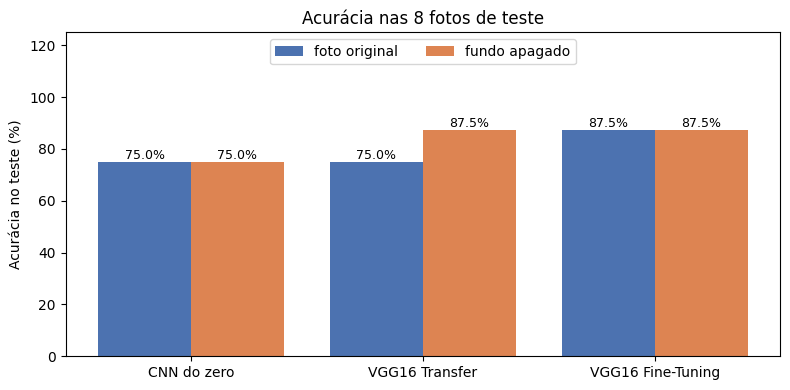

In [18]:
ordem = ['CNN do zero', 'VGG16 Transfer', 'VGG16 Fine-Tuning']
pivo = dados.pivot(index='modelo', columns='base', values='acuracia_teste').reindex(ordem)

posicoes = np.arange(len(ordem))
fig, eixo = plt.subplots(figsize=(8, 4))
barras_o = eixo.bar(posicoes - 0.2, pivo['original'] * 100, width=0.4, label='foto original', color='#4C72B0')
barras_s = eixo.bar(posicoes + 0.2, pivo['segmentado'] * 100, width=0.4, label='fundo apagado', color='#DD8452')
eixo.bar_label(barras_o, fmt='%.1f%%', fontsize=9)
eixo.bar_label(barras_s, fmt='%.1f%%', fontsize=9)
eixo.set_xticks(posicoes, ordem)
eixo.set_ylabel('Acurácia no teste (%)')
eixo.set_ylim(0, 125)
eixo.set_title('Acurácia nas 8 fotos de teste')
eixo.legend(loc='upper center', ncol=2)
plt.tight_layout()
plt.savefig(FIGURAS / 'comparacao_acuracia.png', dpi=110)
plt.show()

## C3. Curvas de treino

Perda na validação a cada época. O Fine-Tuning parte dos pesos obtidos no Transfer Learning, mas sua curva representa uma nova etapa de treinamento e começa sua própria contagem de épocas. Uma elevação da perda de validação ao longo das épocas pode indicar *overfitting*, mas não comprova, por si só, que a rede decorou as fotos de treino. O *Early Stopping* volta à época de menor perda.

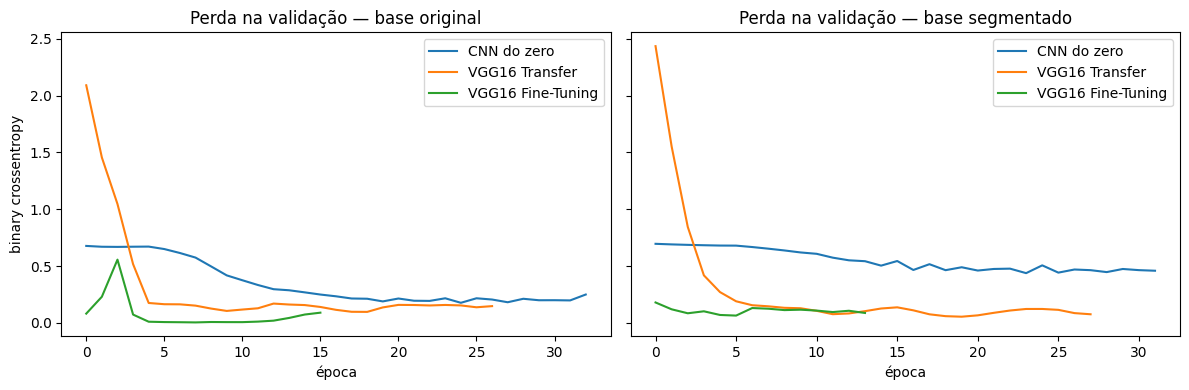

In [19]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for eixo, (nome_base, resultados) in zip(eixos, [('original', resultados_original),
                                                  ('segmentado', resultados_segmentado)]):
    for r in resultados:
        eixo.plot(r['historico']['val_loss'], label=r['modelo'])
    eixo.set_title(f'Perda na validação — base {nome_base}')
    eixo.set_xlabel('época')
    eixo.legend()
eixos[0].set_ylabel('binary crossentropy')
plt.tight_layout()
plt.savefig(FIGURAS / 'curvas_validacao.png', dpi=110)
plt.show()

## C4. Matrizes de confusão e fotos erradas

As linhas mostram a classe verdadeira e as colunas, a classe prevista. Com a diagonal cheia (4 e 4), o modelo acertou tudo. Abaixo das matrizes aparece a lista das fotos de teste classificadas errado em cada treino, com a probabilidade de milho que o modelo deu.

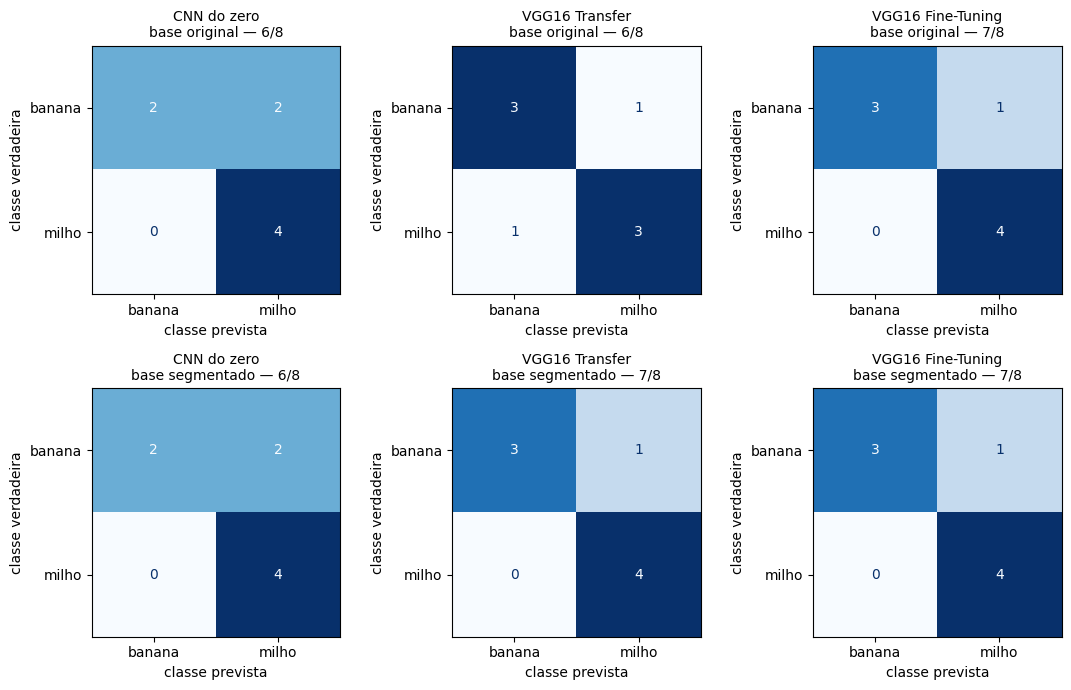

CNN do zero | original: banana_01.jpg (verdadeiro: banana, prob. milho 0.86), banana_02.jpg (verdadeiro: banana, prob. milho 0.81)
VGG16 Transfer | original: banana_01.jpg (verdadeiro: banana, prob. milho 0.83), milho_02.jpg (verdadeiro: milho, prob. milho 0.07)
VGG16 Fine-Tuning | original: banana_01.jpg (verdadeiro: banana, prob. milho 0.99)
CNN do zero | segmentado: banana_01.jpg (verdadeiro: banana, prob. milho 0.87), banana_02.jpg (verdadeiro: banana, prob. milho 0.66)
VGG16 Transfer | segmentado: banana_01.jpg (verdadeiro: banana, prob. milho 0.83)
VGG16 Fine-Tuning | segmentado: banana_01.jpg (verdadeiro: banana, prob. milho 0.60)


In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, eixos = plt.subplots(2, 3, figsize=(11, 7))
for eixo, r in zip(eixos.ravel(), todos):
    matriz = confusion_matrix(r['y_teste'], r['previsoes'], labels=[0, 1])
    ConfusionMatrixDisplay(matriz, display_labels=CLASSES).plot(ax=eixo, colorbar=False, cmap='Blues')
    eixo.set_title(f"{r['modelo']}\nbase {r['base']} — {r['acertos_teste']}/8", fontsize=10)
    eixo.set_xlabel('classe prevista')
    eixo.set_ylabel('classe verdadeira')
plt.tight_layout()
plt.savefig(FIGURAS / 'matrizes_confusao.png', dpi=110)
plt.show()

for r in todos:
    erradas = [f"{foto} (verdadeiro: {CLASSES[v]}, prob. milho {p:.2f})"
               for foto, v, prev, p in zip(r['fotos_teste'], r['y_teste'], r['previsoes'], r['probabilidades'])
               if v != prev]
    print(f"{r['modelo']} | {r['base']}: {', '.join(erradas) if erradas else 'nenhum erro'}")

## C5. As duas hipóteses

A célula compara os números da tabela e diz, para cada hipótese, se o resultado a confirma. Com 8 fotos de teste, uma diferença de **uma foto** (12,5 pontos) pode ser acaso. Por isso, a célula só chama de **confirmada** uma vantagem de pelo menos 2 fotos. Abaixo disso, o resultado aparece como **inconclusivo**.

In [21]:
def acuracia(resultados, modelo):
    return next(r['acertos_teste'] for r in resultados if r['modelo'] == modelo)


def veredito(diferenca):
    if diferenca >= 2:
        return 'CONFIRMADA'
    if diferenca <= -2:
        return 'REJEITADA (o resultado foi o contrário)'
    return 'INCONCLUSIVA (diferença de até 1 foto)'


print('Hipótese 1 — a rede pré-treinada classifica melhor que a CNN do zero?')
for nome_base, resultados in [('original', resultados_original), ('segmentado', resultados_segmentado)]:
    zero = acuracia(resultados, 'CNN do zero')
    melhor_vgg = max(acuracia(resultados, 'VGG16 Transfer'), acuracia(resultados, 'VGG16 Fine-Tuning'))
    print(f'  base {nome_base:10s}: CNN do zero {zero}/8 × melhor VGG16 {melhor_vgg}/8 -> {veredito(melhor_vgg - zero)}')

print()
print('Hipótese 2 — apagar o fundo facilita a classificação?')
for modelo in ordem:
    antes = acuracia(resultados_original, modelo)
    depois = acuracia(resultados_segmentado, modelo)
    print(f'  {modelo:18s}: original {antes}/8 × sem fundo {depois}/8 -> {veredito(depois - antes)}')

Hipótese 1 — a rede pré-treinada classifica melhor que a CNN do zero?
  base original  : CNN do zero 6/8 × melhor VGG16 7/8 -> INCONCLUSIVA (diferença de até 1 foto)
  base segmentado: CNN do zero 6/8 × melhor VGG16 7/8 -> INCONCLUSIVA (diferença de até 1 foto)

Hipótese 2 — apagar o fundo facilita a classificação?
  CNN do zero       : original 6/8 × sem fundo 6/8 -> INCONCLUSIVA (diferença de até 1 foto)
  VGG16 Transfer    : original 6/8 × sem fundo 7/8 -> INCONCLUSIVA (diferença de até 1 foto)
  VGG16 Fine-Tuning : original 7/8 × sem fundo 7/8 -> INCONCLUSIVA (diferença de até 1 foto)


# Conclusões

## Como ler os resultados

**Hipótese 1 — rede pré-treinada × CNN do zero.** A VGG16 chega com 14,7 milhões de pesos já ajustados em 1,2 milhão de fotos do ImageNet. A CNN do zero aprende tudo a partir de 64 fotos. Com tão pouco dado, o esperado é que a VGG16 acerte mais e com probabilidades mais firmes, longe de 0,5. O tempo de treino conta a favor da CNN do zero, que é bem menor. O tempo de inferência por foto conta a favor dela também.

**Hipótese 2 — fundo apagado.** O dataset tem uma particularidade: a maioria das bananas vem de fotos de estúdio com **fundo branco** (base do Kaggle), enquanto os milhos estão no **campo**, entre palha e folhas. É plausível que uma rede use pistas do fundo, além das características do objeto. Com o fundo apagado, essa pista é alterada e a imagem segmentada ainda pode conter artefatos, como o fundo preto. Por isso, o resultado da hipótese 2 pode ir em duas direções:

- **a acurácia sobe ou se mantém:** o resultado é compatível com a hipótese de que as características do objeto contribuam para a classificação; por si só, não demonstra que o modelo será mais confiável para fotos com outros fundos;
- **a acurácia cai:** o resultado é compatível com a hipótese de que pistas do fundo contribuíam para a classificação, mas não comprova essa causa nem torna necessariamente enganosa a acurácia com a foto original.

Nas duas situações, a segmentação revela algo sobre o que o modelo realmente aprendeu.

## Pontos fortes

- Segmentação **100% automática**: o YOLOv5 da Entrega 1 indica a posição e o SAM desenha o contorno. Nenhuma máscara foi feita à mão.
- Comparação controlada: as mesmas fotos, a mesma divisão, o mesmo tamanho de imagem, o mesmo aumento de dados e a mesma semente nas seis combinações modelo × base.
- Conferência objetiva das máscaras (IoU de caixa contra os rótulos do MakeSense) e demonstração visual de original, máscara e foto sem fundo.
- A classe prevista pelo YOLOv5 é descartada na segmentação, então o classificador não recebe a resposta.
- Inspeção visual das máscaras: ela revelou que o SAM às vezes devolvia o fundo no lugar do objeto, falha que o IoU de caixa não detectava. A correção automática (seção A3) desinverte essas máscaras sem usar os rótulos.

## Limitações

- **Teste muito pequeno.** São 8 fotos: cada erro vale 12,5 pontos. O grupo adotou, como heurística descritiva, uma diferença mínima de 2 imagens para evitar conclusões fortes quando a diferença é de apenas uma imagem; esse critério não representa significância estatística. Repetir com outras sementes ou com mais fotos tornaria as conclusões mais firmes.
- **A validação também é pequena** (8 fotos). A época escolhida pelo *Early Stopping* pode variar bastante entre execuções.
- **A segmentação depende do detector da Entrega 1.** O YOLOv5 foi treinado com as mesmas fotos de treino, então nelas ele tende a acertar mais do que acertaria em fotos novas. Quando ele erra a caixa, o SAM recorta a região errada.
- **A segmentação ainda erra em alguns casos.** A correção resolve as máscaras invertidas, mas não as que pegam só parte do objeto (como `banana_02`, em que a caixa cobriu uma banana de um cacho grande). A regra dos 60% da borda é uma heurística: na `milho_03`, a espiga atravessa a caixa de ponta a ponta e a máscara continuou invertida.
- **Fundo preto não é "fundo nenhum".** A rede ainda vê a silhueta e a proporção do objeto contra o preto, e aprende a partir disso também.
- **O redimensionamento para 224 × 224 achata as fotos** que não são quadradas, o que muda a proporção do objeto.

## Resultados da execução de 07/10/2026

Execução completa no Colab com GPU T4, usando o `best.pt` da simulação de 60 épocas da Entrega 1. Com a semente fixa, a rodada com as fotos originais foi repetida e deu os mesmos acertos.

| Modelo | Fotos originais | Fotos sem fundo |
| --- | --- | --- |
| CNN do zero | 6/8 (validação 100%) | 6/8 (validação 75%) |
| VGG16 Transfer | 6/8 (validação 88%) | 7/8 (validação 100%) |
| VGG16 Fine-Tuning | 7/8 (validação 100%) | 7/8 (validação 100%) |

**Hipótese 1 — inconclusiva, com sinal a favor da VGG16.** Nas duas versões da base, a melhor VGG16 acertou 7 de 8 e a CNN do zero, 6 de 8. A diferença é de uma foto, abaixo da heurística descritiva de 2 imagens adotada pelo grupo para evitar conclusões fortes com diferença de apenas uma imagem; ela não representa significância estatística. A VGG16 nunca ficou atrás da CNN. Em troca, a CNN treina mais rápido (10 a 14 s, contra 19 a 34 s das VGG16) e classifica cada foto em cerca de 20 ms, contra 36 a 53 ms.

**Hipótese 2 — inconclusiva, com um sinal importante.** A VGG16 Transfer passou de 6 para 7 acertos com o fundo apagado (a `milho_02`, espigas num prato sobre mesa de madeira, deixou de ser confundida). As outras redes mantiveram os acertos. O sinal mais claro está na validação: sem o fundo, a CNN do zero caiu de 100% para 75%, enquanto as VGG16 ficaram em 100%. Nesta execução, a queda da CNN é compatível com a hipótese de que pistas do fundo contribuíam para suas previsões; os resultados não comprovam essa causa nem permitem afirmar que a VGG16 se apoiou mais na forma e na textura do objeto.

**A foto que todos erraram.** A `banana_01` foi classificada como milho nas seis combinações modelo × base. Uma hipótese plausível para o erro é que a imagem mostra o coração da bananeira (a flor roxa), e não o fruto; além disso, o fundo de folhas verdes difere do fundo branco de muitas fotos de banana. Esses aspectos podem ter contribuído, mas os resultados não comprovam a causa do erro. Com o fundo apagado, a confiança no erro caiu na VGG16 Fine-Tuning (probabilidade de milho de 0,99 para 0,60), mas não o suficiente para virar acerto. A foto vale ser revista na curadoria: se a classe é o fruto, o coração da bananeira pode não representá-la.

**Segmentação e erros.** A correção das máscaras invertidas fez o teste passar de 4 para 6 fotos bem recortadas, de 8. Continuam com problema a `banana_02` (só um pedaço do cacho foi recortado), que a CNN do zero errou nas duas versões, e a `milho_03` (máscara ainda invertida, porque a espiga atravessa a caixa de ponta a ponta e a palha cobre menos de 60% da borda), que todos os modelos acertaram mesmo assim.

**Conclusão.** Com 8 fotos de teste, nenhuma das hipóteses pode ser confirmada pelo critério adotado. Nesta execução, a rede pré-treinada apresentou resultados mais estáveis e foi menos afetada pela remoção do fundo; a queda observada na validação da CNN do zero é compatível com a hipótese de que pistas do fundo contribuíam para suas previsões, mas não estabelece causalidade. Para uma conclusão firme, o próximo passo é ampliar o teste e repetir os treinos com outras sementes.

## Referências

- FIAP. Capítulo 9 — *Desbravando o Deep Learning: Primeiros Passos com CNN* (Transfer Learning com VGG16).
- FIAP. Capítulo 10 — *O Olhar Digital: Técnicas de Detecção e Segmentação* (YOLO, SAM e IoU).
- KIRILLOV, A. et al. *Segment Anything*. ICCV, 2023.
- SIMONYAN, K.; ZISSERMAN, A. *Very Deep Convolutional Networks for Large-Scale Image Recognition* (VGG16). 2014.
- Ultralytics. [YOLOv5](https://github.com/ultralytics/yolov5) e [SAM](https://docs.ultralytics.com/models/sam/).
- Keras. [VGG16](https://keras.io/api/applications/vgg/) e [Transfer learning & fine-tuning](https://keras.io/guides/transfer_learning/).